# EDA: what limits should the API accept?

The main goal of this notebook is to determine the range I should put in the individual fields in `PredictRequest`.

I will use the following to guide me:

- **Impossible values**: negative income, a latitude outside California.
- **Unusual but real values** should usually be accepted. Homes with hundreds of occupants on average.

## 1. Load the data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml_api.data import FEATURES, TARGET, load_data

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 20)

df = load_data()
df.shape

(20640, 9)

In [2]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,"2,401.000",2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 2. Types and missing values

In [4]:
pd.DataFrame(
    {
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "unique values": df.nunique(),
    }
)

,dtype,missing,unique values
MedInc,float64,0,12928
HouseAge,float64,0,52
AveRooms,float64,0,19392
AveBedrms,float64,0,14233
Population,float64,0,3888
AveOccup,float64,0,18841
Latitude,float64,0,862
Longitude,float64,0,844
MedHouseVal,float64,0,3842


## 3. The full spread of every column

In [5]:
df.describe(percentiles=[0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T

,count,mean,std,min,0.1%,1%,25%,50%,75%,99%,99.9%,max
MedInc,"20,640.000",3.871,1.900,0.500,0.536,1.070,2.563,3.535,4.743,10.597,15.000,15.000
HouseAge,"20,640.000",28.639,12.586,1.000,2.000,4.000,18.000,29.000,37.000,52.000,52.000,52.000
AveRooms,"20,640.000",5.429,2.474,0.846,1.750,2.581,4.441,5.229,6.052,10.357,34.200,141.909
AveBedrms,"20,640.000",1.097,0.474,0.333,0.675,0.873,1.006,1.049,1.100,2.128,6.617,34.067
Population,"20,640.000","1,425.477","1,132.462",3.000,17.639,88.000,787.000,"1,166.000","1,725.000","5,805.830","10,372.681","35,682.000"
AveOccup,"20,640.000",3.071,10.386,0.692,1.299,1.537,2.430,2.818,3.282,5.395,13.630,"1,243.333"
Latitude,"20,640.000",35.632,2.136,32.540,32.570,32.680,33.930,34.260,37.710,40.626,41.754,41.950
Longitude,"20,640.000",-119.570,2.004,-124.350,-124.180,-123.220,-121.800,-118.490,-118.010,-116.290,-114.646,-114.310
MedHouseVal,"20,640.000",2.069,1.154,0.150,0.331,0.500,1.196,1.797,2.647,5.000,5.000,5.000


## 4. Distributions

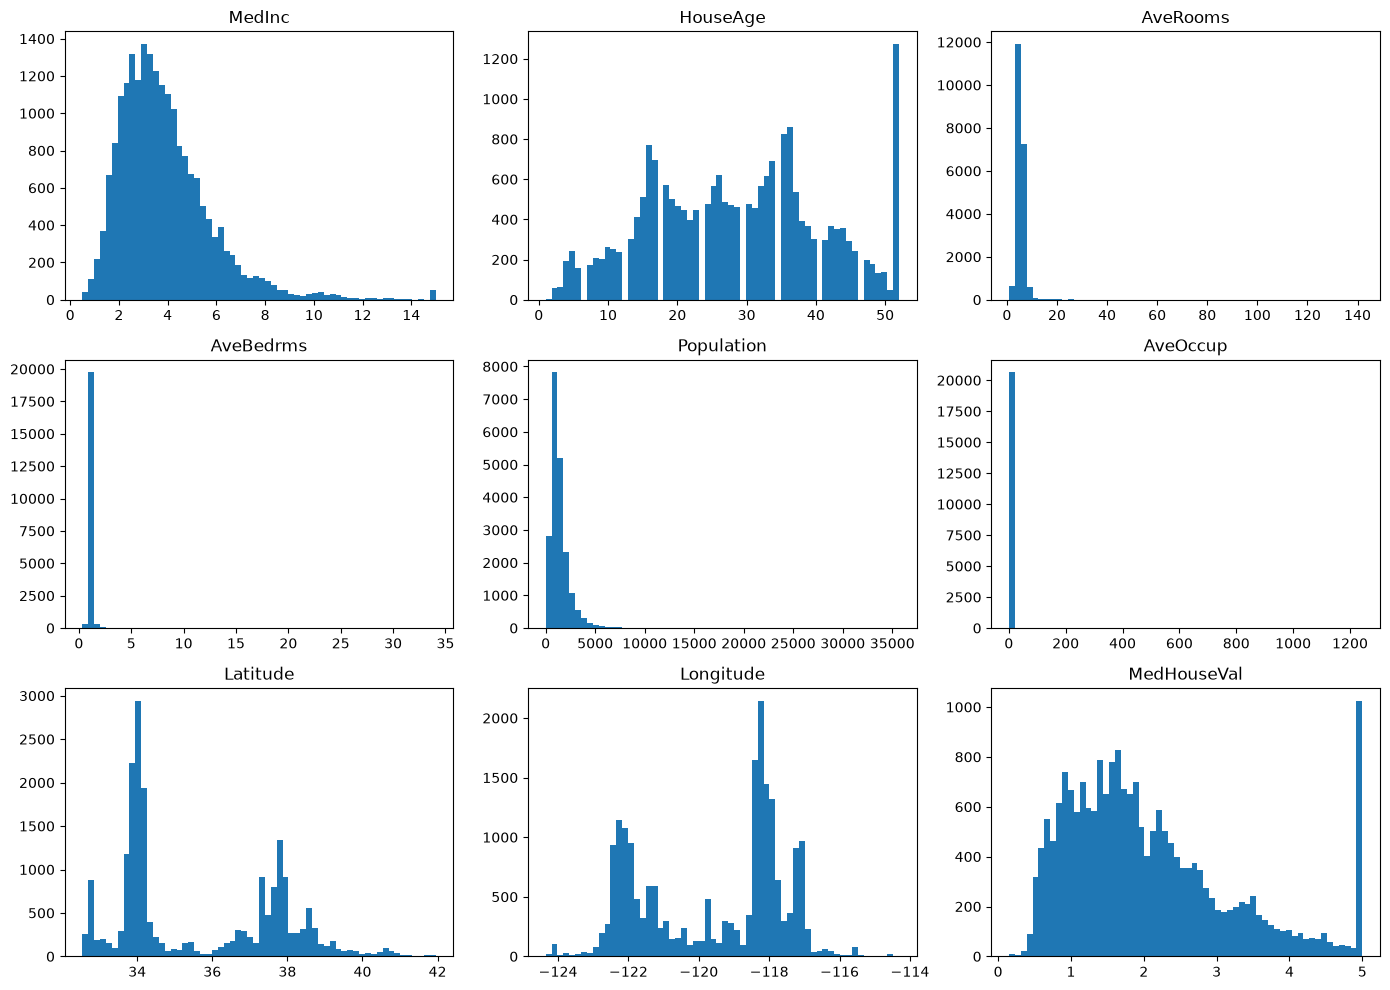

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, FEATURES + [TARGET], strict=True):
    ax.hist(df[col], bins=60)
    ax.set_title(col)
fig.tight_layout()
plt.show()

## 5. Log plots of extremely right skewed attributes

Long-tailed columns: ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']


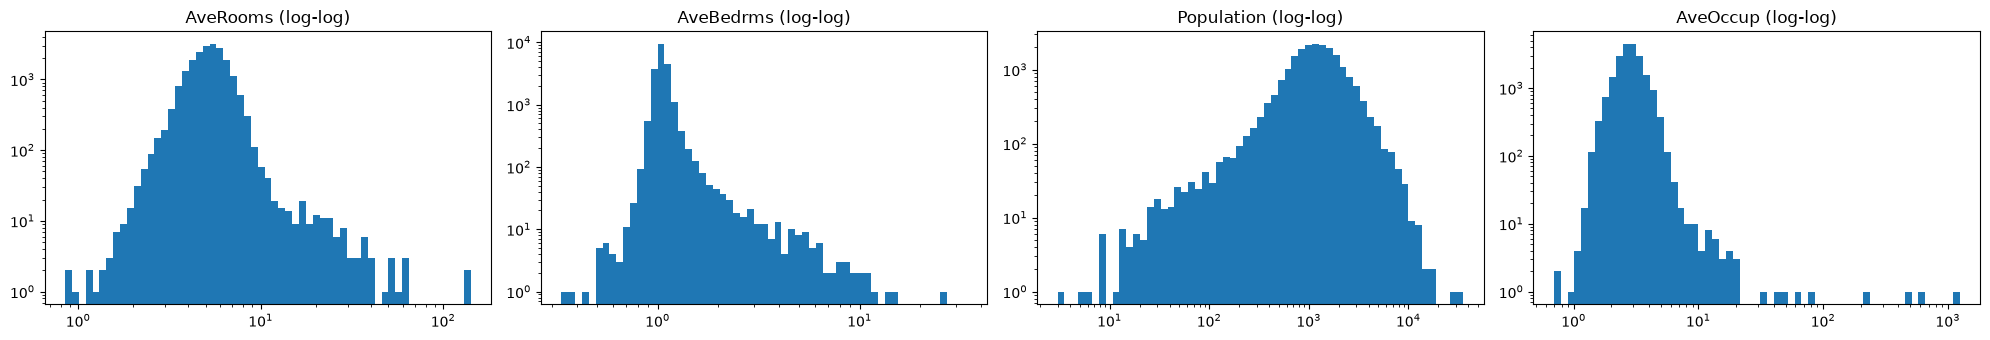

In [10]:
q999 = df[FEATURES].quantile(0.999)
long_tailed = [c for c in FEATURES if df[c].max() > 3 * q999[c] and df[c].min() > 0]
print("Long-tailed columns:", long_tailed)

if long_tailed:
    n = len(long_tailed)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 3.5), squeeze=False)
    for ax, col in zip(axes.flat, long_tailed, strict=True):
        ax.hist(df[col], bins=np.logspace(np.log10(df[col].min()), np.log10(df[col].max()), 60))
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{col} (log-log)")
    fig.tight_layout()
plt.show()

In [11]:
# The five most extreme rows for one column. Change the name and re-run.
col = "AveOccup"
df.sort_values(col, ascending=False).head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.226,45.000,3.167,0.833,"7,460.000","1,243.333",38.320,-121.980,1.375
3364,5.518,36.000,5.143,1.143,"4,198.000",599.714,40.410,-120.510,0.675
16669,4.264,46.000,9.077,1.308,"6,532.000",502.462,35.320,-120.700,3.500
13034,6.136,52.000,8.276,1.517,"6,675.000",230.172,38.690,-121.150,2.250
9172,4.239,5.000,5.124,0.933,"8,733.000",83.171,34.470,-118.590,1.546


## 6. Capped values

In [12]:
at_max = pd.DataFrame(
    {
        "max": df[FEATURES + [TARGET]].max(),
        "rows at max": [(df[c] == df[c].max()).sum() for c in FEATURES + [TARGET]],
    }
)
at_max["share at max"] = at_max["rows at max"] / len(df)
at_max.sort_values("rows at max", ascending=False)

,max,rows at max,share at max
HouseAge,52.000,1273,0.062
MedHouseVal,5.000,965,0.047
MedInc,15.000,49,0.002
Latitude,41.950,2,0.000
AveRooms,141.909,1,0.000
Population,"35,682.000",1,0.000
AveBedrms,34.067,1,0.000
AveOccup,"1,243.333",1,0.000
Longitude,-114.310,1,0.000


## 7. Rules between columns

In [13]:
broken = df[df["AveBedrms"] > df["AveRooms"]]
print(f"{len(broken)} rows have more bedrooms than rooms")
broken.head()

0 rows have more bedrooms than rooms


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal


## 8. Location

Every block is in California, so latitude and longitude only make sense inside the state's bounding box. The plot also shows where the expensive blocks are.

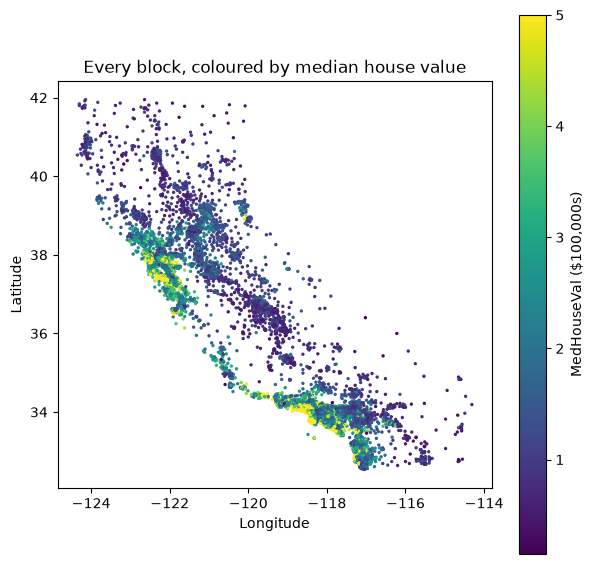

In [14]:
fig, ax = plt.subplots(figsize=(7, 7))
points = ax.scatter(df["Longitude"], df["Latitude"], c=df[TARGET], s=2, cmap="viridis")
fig.colorbar(points, label=f"{TARGET} ($100,000s)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.set_title("Every block, coloured by median house value")
plt.show()

## 9. Draft the limits

Creating a table that shows a suggested minimum and maximum value, then I will transfer that to `schema.py` asking the following three questions modifying the values if needed.

1. What is physically impossible? That is the hard limit.
2. Is the column capped? Then values above the cap are real, but the model treats them all as the cap.
3. Are the extreme rows errors or real places?

In [17]:
NON_NEGATIVE = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup"]

stats = df[FEATURES].agg(["min", "max"]).T
stats["p0.1"] = df[FEATURES].quantile(0.001)
stats["p99.9"] = df[FEATURES].quantile(0.999)
span = stats["max"] - stats["min"]
stats["suggested min"] = stats["min"] - 0.1 * span
stats["suggested max"] = stats["max"] + 0.1 * span
stats.loc[NON_NEGATIVE, "suggested min"] = stats.loc[NON_NEGATIVE, "suggested min"].clip(lower=0)

display(stats)

,min,max,p0.1,p99.9,suggested min,suggested max
MedInc,0.500,15.000,0.536,15.000,0.000,16.450
HouseAge,1.000,52.000,2.000,52.000,0.000,57.100
AveRooms,0.846,141.909,1.750,34.200,0.000,156.015
AveBedrms,0.333,34.067,0.675,6.617,0.000,37.440
Population,3.000,"35,682.000",17.639,"10,372.681",0.000,"39,249.900"
AveOccup,0.692,"1,243.333",1.299,13.630,0.000,"1,367.597"
Latitude,32.540,41.950,32.570,41.754,31.599,42.891
Longitude,-124.350,-114.310,-124.180,-114.646,-125.354,-113.306


## 10. My decisions

| Field | Lower limit | Upper limit |
| --- | --- | --- |
| `median_income` | 0 | 20 |
| `house_age` | 0 | 100 |
| `avg_rooms` | 0 | 150 |
| `avg_bedrooms` | 0 | 38 |
| `population` | 0 | 40,000,000 |
| `avg_occupancy` | 0 | 1400 |
| `latitude` | 30 | 43 |
| `longitude` | -126 | -113 |